# Mission : pilote automatique pour l'atterrissage d'Eagle-1

AstroDynamics développe des systèmes autonomes pour l'exploration spatiale. Le module Eagle-1 doit se poser sur une zone cible lunaire avec précision et en douceur, en consommant le moins de carburant possible.

La simulation est `LunarLander-v3` de Gymnasium. Critère de succès de la mission : récompense moyenne supérieure ou égale à 200 sur 100 épisodes consécutifs.

## Étape 1 : explorer l'environnement et établir une base de référence

Les espaces d'observation et d'action, et 2 points de comparaison : une politique aléatoire, et un premier agent DQN laissé avec les hyperparamètres par défaut (ces deux scores servent de repère pour la suite).

In [ ]:
# Les librairies nécessaires pour cette mission.
%pip install -q "gymnasium[box2d]" stable-baselines3 matplotlib

In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import stable_baselines3
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

SEED = 0

print("Version de Gymnasium          :", gym.__version__)
print("Version de Stable-Baselines3  :", stable_baselines3.__version__)

Version de Gymnasium          : 1.3.0
Version de Stable-Baselines3  : 2.9.0


## Exploration de l'environnement

`LunarLander-v3` simule l'atterrissage d'un module lunaire. Le module apparaît en haut de l'écran et doit se poser entre les deux drapeaux, au centre en bas.

In [3]:
env = gym.make("LunarLander-v3")

print("Espace d'observation      :", env.observation_space)
print("Espace d'action           :", env.action_space)
print("Steps maximum par épisode :", env.spec.max_episode_steps)
print("Seuil de résolution       :", env.spec.reward_threshold)

Espace d'observation      : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'action           : Discrete(4)
Steps maximum par épisode : 1000
Seuil de résolution       : 200


In [4]:
noms_observations = [
    "Position horizontale",
    "Position verticale",
    "Vitesse horizontale",
    "Vitesse verticale",
    "Angle du module",
    "Vitesse de rotation",
    "Contact de la jambe gauche",
    "Contact de la jambe droite",
]

print("Ce que l'agent voit :")
for i, nom in enumerate(noms_observations):
    borne_basse = env.observation_space.low[i]
    borne_haute = env.observation_space.high[i]
    print(f"  valeur {i} : {nom:28s} de {borne_basse:+7.2f} à {borne_haute:+6.2f}")

Ce que l'agent voit :
  valeur 0 : Position horizontale         de   -2.50 à  +2.50
  valeur 1 : Position verticale           de   -2.50 à  +2.50
  valeur 2 : Vitesse horizontale          de  -10.00 à +10.00
  valeur 3 : Vitesse verticale            de  -10.00 à +10.00
  valeur 4 : Angle du module              de   -6.28 à  +6.28
  valeur 5 : Vitesse de rotation          de  -10.00 à +10.00
  valeur 6 : Contact de la jambe gauche   de   -0.00 à  +1.00
  valeur 7 : Contact de la jambe droite   de   -0.00 à  +1.00


In [5]:
noms_actions = [
    "Ne rien faire",
    "Allumer le moteur d'orientation gauche",
    "Allumer le moteur principal",
    "Allumer le moteur d'orientation droit",
]

print("Ce que l'agent peut faire :")
for i, nom in enumerate(noms_actions):
    print(f"  action {i} : {nom}")

Ce que l'agent peut faire :
  action 0 : Ne rien faire
  action 1 : Allumer le moteur d'orientation gauche
  action 2 : Allumer le moteur principal
  action 3 : Allumer le moteur d'orientation droit


Les six premières valeurs sont continues. Les deux dernières valent 0 ou 1 selon qu'une jambe touche le sol.

La récompense combine plusieurs termes. Se rapprocher de la zone d'atterrissage rapporte des points, aller vite ou pencher coûte des points. Chaque jambe qui touche le sol rapporte 10 points. Allumer le moteur principal coûte 0,3 point par image, un moteur d'orientation 0,03. Il y a aussi une contrainte de carburant. L'épisode se termine sur 100 points pour un atterrissage réussi, ou -100 pour un crash.

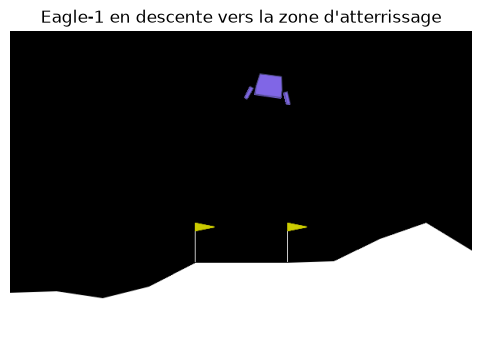

In [6]:
env_visuel = gym.make("LunarLander-v3", render_mode="rgb_array")
env_visuel.reset(seed=SEED)

# Quelques steps de chute libre, sinon le module est colle tout en haut de l'image
for _ in range(20):
    env_visuel.step(0)

image = env_visuel.render()
env_visuel.close()

plt.figure(figsize=(6, 4))
plt.imshow(image)
plt.axis("off")
plt.title("Eagle-1 en descente vers la zone d'atterrissage")
plt.show()

## Base de référence : une politique aléatoire

L'agent tire ses actions au hasard, avant tout apprentissage.

In [7]:
env.reset(seed=SEED)
env.action_space.seed(SEED)

recompenses_hasard = []

for episode in range(100):
    env.reset()
    terminated = False
    truncated = False
    total_reward = 0.0
    while not terminated and not truncated:
        _, reward, terminated, truncated, _ = env.step(env.action_space.sample())
        total_reward += reward
    recompenses_hasard.append(total_reward)

env.close()

print("Politique aléatoire sur 100 épisodes")
print(f"  moyenne    : {np.mean(recompenses_hasard):8.1f}")
print(f"  écart-type : {np.std(recompenses_hasard):8.1f}")
print(f"  minimum    : {min(recompenses_hasard):8.1f}")
print(f"  maximum    : {max(recompenses_hasard):8.1f}")

Politique aléatoire sur 100 épisodes

  moyenne    :   -165.1
  écart-type :     94.3
  minimum    :   -478.3
  maximum    :     -3.2


## Premier agent : DQN avec les hyperparamètres par défaut

L'espace d'action est `Discrete(4)`, donc discret, et DQN convient (PPO serait le choix pour un espace continu).

On prend les valeurs par défaut de Stable-Baselines3 et on entraîne sur 100 000 steps.

Seed fixée : d'une exécution à l'autre le résultat varie de plusieurs dizaines de points (on comparera à l'étape suivante).

In [8]:
env_entrainement = Monitor(gym.make("LunarLander-v3"))

modele = DQN("MlpPolicy", env_entrainement, verbose=1, seed=SEED)
modele.learn(total_timesteps=100_000, log_interval=100)

Using cpu device
Wrapping the env in a DummyVecEnv.


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 233      |
|    ep_rew_mean      | -228     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 100      |
|    fps              | 2126     |
|    time_elapsed     | 10       |
|    total_timesteps  | 23327    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.594    |
|    n_updates        | 5806     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 442      |
|    ep_rew_mean      | -103     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 200      |
|    fps              | 1967     |
|    time_elapsed     | 34       |
|    total_timesteps  | 67574    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.664    |
|    n_updates        | 16868    |
----------------------------------


In [9]:
recompense_moyenne, ecart_type = evaluate_policy(modele, env_entrainement, n_eval_episodes=100)

print(f"Récompense moyenne sur 100 épisodes : {recompense_moyenne:8.1f} +/- {ecart_type:.1f}")
print(f"Objectif de la mission              : {200.0:8.1f}")

env_entrainement.close()

Récompense moyenne sur 100 épisodes :   -100.6 +/- 85.4
Objectif de la mission              :    200.0


## Ce que donne cette base de référence

L'agent par défaut fait mieux que la politique aléatoire. L'apprentissage fonctionne, le pipeline est ok de bout en bout.

Il reste très loin des 200 demandés (sa récompense est encore négative) : il ne se pose pas, il s'écrase moins brutalement. L'écart-type est large, le comportement change beaucoup d'un épisode à l'autre.

Les hyperparamètres par défaut de Stable-Baselines3 sont calibrés pour les jeux Atari, pas pour un environnement de contrôle comme celui-ci.

## Étape 2 : optimisation des hyperparamètres

On repart de l'agent par défaut de l'étape 1. Cible : récompense moyenne supérieure à 200 sur 100 épisodes, avec un écart-type faible.

On change un seul hyperparamètre à la fois, sur le même budget de 100 000 steps que la référence. Isolé comme ça, on voit lequel compte. On cumule ensuite les changements et on allonge l'entraînement. Et on finit en essayant un autre algorithme.

Tout est logué dans TensorBoard, pour superposer les courbes ensuite.

In [10]:
import glob

from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

DOSSIER_LOGS = "./logs_mission/"


def experience(nom, reglages, total_timesteps=100_000, n_eval_episodes=100):
    """Entraine un DQN avec les reglages donnes, journalise, puis evalue."""
    env = Monitor(gym.make("LunarLander-v3"))
    modele = DQN("MlpPolicy", env, verbose=0, seed=SEED,
                 tensorboard_log=DOSSIER_LOGS, **reglages)
    modele.learn(total_timesteps=total_timesteps, tb_log_name=nom)

    scores, _ = evaluate_policy(modele, env, n_eval_episodes=n_eval_episodes,
                                return_episode_rewards=True)
    env.close()
    scores = np.array(scores)
    return {
        "nom": nom,
        "moyenne": scores.mean(),
        "ecart_type": scores.std(),
        "mediane": float(np.median(scores)),
        "au_dessus_200": int((scores > 200).sum()),
        "pire": scores.min(),
        "modele": modele,
    }


def courbe(nom):
    """Relit la courbe de recompense d'une experience dans ses logs TensorBoard."""
    fichiers = sorted(glob.glob(f"{DOSSIER_LOGS}/{nom}_*/events*"))
    accumulateur = EventAccumulator(fichiers[-1])
    accumulateur.Reload()
    points = accumulateur.Scalars("rollout/ep_rew_mean")
    return [p.step for p in points], [p.value for p in points]


def afficher(resultats):
    """Tableau recapitulatif des experiences."""
    print(f"{'expérience':<22}{'moyenne':>9}{'écart-type':>12}{'médiane':>9}{'>200':>7}{'pire':>9}")
    for r in resultats:
        print(f"{r['nom']:<22}{r['moyenne']:>9.1f}{r['ecart_type']:>12.1f}"
              f"{r['mediane']:>9.1f}{r['au_dessus_200']:>7d}{r['pire']:>9.1f}")

### Une modification à la fois

5 variantes qui changent qu'une seule valeur par rapport aux défauts de l'étape 1. Le brief parle de `learning_rate`, `gamma` et `buffer_size`. Le `target_update_interval` et la taille du réseau sont les deux plus gros écarts entre les valeurs par défaut et la configuration que le RL Zoo publie pour cet environnement.

La ligne `defauts` reprend la configuration de l'étape 1.

In [11]:
variantes = [
    ("defauts",       {}),
    ("learning_rate", {"learning_rate": 6.3e-4}),
    ("gamma",         {"gamma": 0.999}),
    ("buffer_size",   {"buffer_size": 50_000}),
    ("target_update", {"target_update_interval": 250}),
    ("reseau_256",    {"policy_kwargs": dict(net_arch=[256, 256])}),
]

resultats = [experience(nom, reglages) for nom, reglages in variantes]
afficher(resultats)

expérience              moyenne  écart-type  médiane   >200     pire
defauts                  -100.6        85.4   -123.6      5   -169.2
learning_rate            -140.2        34.3   -144.0      0   -201.1
gamma                     -95.6       105.1   -132.4      5   -183.8
buffer_size               -88.2        93.7   -111.5      5   -240.6
target_update              75.5        85.1    102.8      0   -160.0
reseau_256                -90.2       104.0   -129.1      4   -201.4


Une seule variante déplace la moyenne : `target_update_interval`. Le passer de 10 000 à 250 fait basculer le score du négatif au positif (c'est le seul changement qui y arrive).

Avec la valeur par défaut, le réseau cible n'est recopié que 10 fois sur 100 000 steps. La cible vers laquelle l'apprentissage tire reste figée pendant presque tout l'entraînement.

Le `learning_rate` seul dégrade le résultat. Ces réglages ne s'additionnent pas indépendamment.

Aucune variante ne franchit la cible à ce budget.

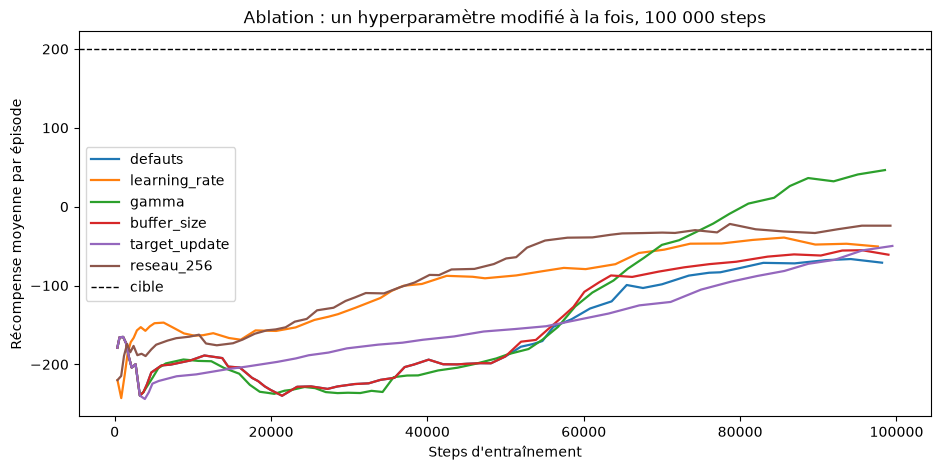

In [12]:
plt.figure(figsize=(11, 5))
for r in resultats:
    x, y = courbe(r["nom"])
    plt.plot(x, y, label=r["nom"], linewidth=1.6)

plt.axhline(200, color="black", linestyle="--", linewidth=1, label="cible")
plt.xlabel("Steps d'entraînement")
plt.ylabel("Récompense moyenne par épisode")
plt.title("Ablation : un hyperparamètre modifié à la fois, 100 000 steps")
plt.legend()
plt.show()

Les courbes et le tableau ne mesurent pas la même chose. `rollout/ep_rew_mean` enregistre le comportement pendant l'entraînement (exploration comprise). `evaluate_policy` rejoue ensuite la politique déterministe, sans exploration.

D'où les classements différents. `target_update` en est le cas typique : courbe d'entraînement médiocre, politique greedy correcte.

### Toutes les modifications réunies, puis budget augmenté

La configuration ci-dessous est celle que le RL Zoo publie pour `LunarLander-v3`. Elle garde `gamma` à 0.99 et ajoute deux réglages que l'ablation ne couvrait pas, `train_freq` et `gradient_steps`.

2 entraînements : le premier au même budget de 100 000 steps, pour voir ce qu'apportent les hyperparamètres seuls. Le second à 400 000 steps, pour voir ce qu'apporte le budget.

In [13]:
CONFIG_COMBINEE = dict(
    learning_rate=6.3e-4,
    batch_size=128,
    buffer_size=50_000,
    learning_starts=0,
    gamma=0.99,
    target_update_interval=250,
    train_freq=4,
    gradient_steps=-1,
    exploration_fraction=0.12,
    exploration_final_eps=0.1,
    policy_kwargs=dict(net_arch=[256, 256]),
)

combinee = experience("combinee_100k", CONFIG_COMBINEE, total_timesteps=100_000)
afficher([combinee])

expérience              moyenne  écart-type  médiane   >200     pire
combinee_100k              67.0       201.6     35.0     40   -539.3


In [14]:
combinee_longue = experience("combinee_400k", CONFIG_COMBINEE, total_timesteps=400_000)
afficher([combinee_longue])

combinee_longue["modele"].save("dqn_lunarlander")
print("\nModèle DQN sauvegardé dans dqn_lunarlander.zip")

expérience              moyenne  écart-type  médiane   >200     pire
combinee_400k             201.5       116.2    236.3     74   -309.9

Modèle DQN sauvegardé dans dqn_lunarlander.zip


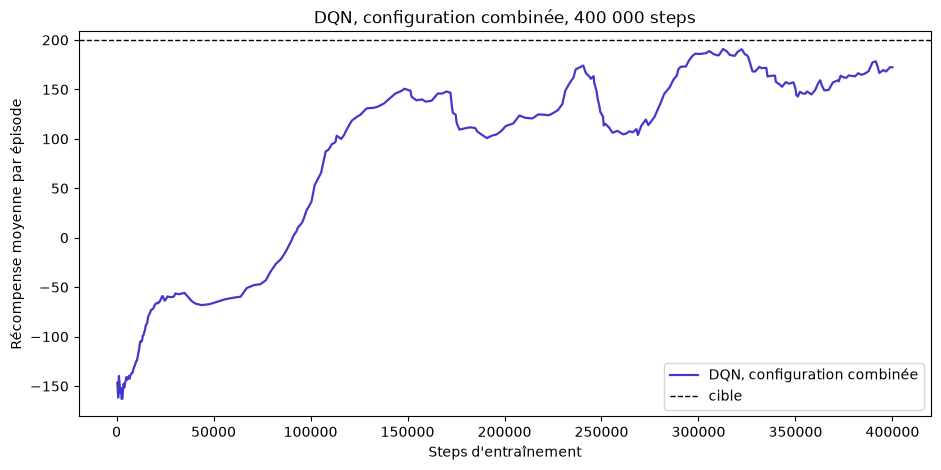

In [15]:
plt.figure(figsize=(11, 5))
x, y = courbe("combinee_400k")
plt.plot(x, y, color="#4338CA", linewidth=1.6, label="DQN, configuration combinée")
plt.axhline(200, color="black", linestyle="--", linewidth=1, label="cible")
plt.xlabel("Steps d'entraînement")
plt.ylabel("Récompense moyenne par épisode")
plt.title("DQN, configuration combinée, 400 000 steps")
plt.legend()
plt.show()

À budget égal, la configuration combinée ne fait pas mieux que le seul `target_update_interval`, et son écart-type explose. Les hyperparamètres seuls ne suffisent donc pas.

Quadrupler le budget fait passer la moyenne au-dessus de 200 sans régler la stabilité : un quart des épisodes reste sous le seuil, l'écart-type dépasse 100, le pire épisode est un vrai crash. La courbe oscille au lieu de monter (l'agent perd puis regagne ce qu'il savait).

Le brief veut un écart-type faible, pas une moyenne obtenue par compensation entre réussites et crashes (on teste donc un autre algorithme).

### Mise en concurrence avec PPO

Le brief autorise à tester PPO, et l'espace d'action de `LunarLander-v3` étant discret, PPO le gère sans adaptation.

On prend la configuration que le RL Zoo publie pour cet environnement : 16 environnements en parallèle, 1 000 000 de steps. Plus de steps que pour DQN, mais la parallélisation rend l'entraînement plus rapide en temps réel.

L'ablation plus haut portait sur DQN. Pour PPO on ne cherche pas les hyperparamètres : ceux du RL Zoo viennent de l'équipe qui maintient Stable-Baselines3, qui les a obtenus par recherche automatique sur ce même environnement (refaire cette recherche ici ne changerait rien au résultat).

In [16]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

env_ppo = make_vec_env("LunarLander-v3", n_envs=16, seed=SEED)

modele_ppo = PPO(
    "MlpPolicy",
    env_ppo,
    verbose=0,
    seed=SEED,
    tensorboard_log=DOSSIER_LOGS,
    n_steps=1024,
    batch_size=64,
    gae_lambda=0.98,
    gamma=0.999,
    n_epochs=4,
    ent_coef=0.01,
)

modele_ppo.learn(total_timesteps=1_000_000, tb_log_name="ppo")
env_ppo.close()
print("Entraînement PPO terminé.")

Entraînement PPO terminé.


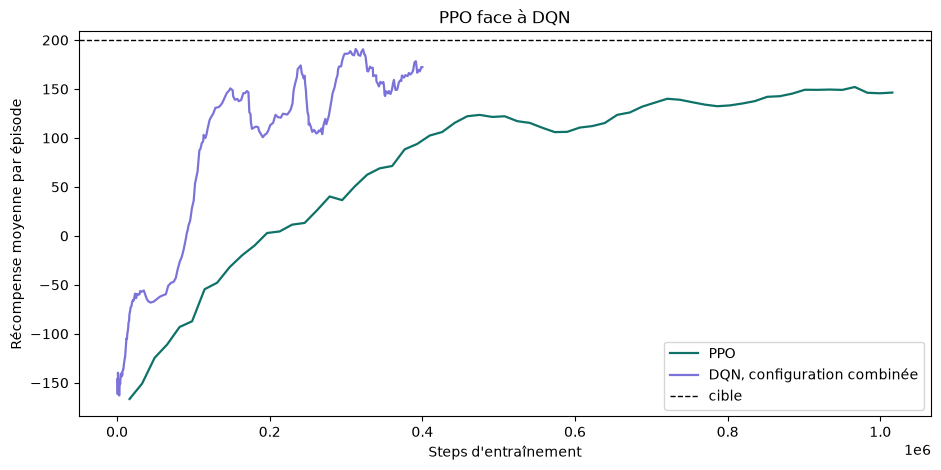

In [17]:
plt.figure(figsize=(11, 5))
x, y = courbe("ppo")
plt.plot(x, y, color="#0E7268", linewidth=1.6, label="PPO")
x, y = courbe("combinee_400k")
plt.plot(x, y, color="#4338CA", linewidth=1.6, alpha=0.7, label="DQN, configuration combinée")
plt.axhline(200, color="black", linestyle="--", linewidth=1, label="cible")
plt.xlabel("Steps d'entraînement")
plt.ylabel("Récompense moyenne par épisode")
plt.title("PPO face à DQN")
plt.legend()
plt.show()

Si on lit en steps, la comparaison avantage DQN : il monte plus vite par step consommé.

Sauf que PPO tourne sur 16 environnements en parallèle, donc son million de steps prend moins de temps réel que les 400 000 steps de DQN (DQN consomme moins d'échantillons et PPO moins de temps).

Et les 2 courbes n'ont pas la même forme. PPO monte régulièrement, DQN oscille de plusieurs dizaines de points d'un relevé à l'autre. Cette oscillation se retrouve ensuite dans l'écart-type de l'évaluation.

### Évaluation finale

100 épisodes avec l'agent retenu, comme le demande la mission.

In [18]:
env_eval = Monitor(gym.make("LunarLander-v3"))
scores_finaux, _ = evaluate_policy(modele_ppo, env_eval, n_eval_episodes=100,
                                   return_episode_rewards=True)
env_eval.close()
scores_finaux = np.array(scores_finaux)

print(f"Récompense moyenne sur 100 épisodes : {scores_finaux.mean():8.1f} +/- {scores_finaux.std():.1f}")
print(f"Médiane                             : {np.median(scores_finaux):8.1f}")
print(f"Épisodes au-dessus de 200           : {(scores_finaux > 200).sum():8d} / 100")
print(f"Pire épisode                        : {scores_finaux.min():8.1f}")
print()
print(f"Critère de la mission, moyenne > 200 : "
      f"{'ATTEINT' if scores_finaux.mean() > 200 else 'NON ATTEINT'}")

modele_ppo.save("ppo_lunarlander")
print("\nModèle sauvegardé dans ppo_lunarlander.zip")

Récompense moyenne sur 100 épisodes :    258.1 +/- 23.8
Médiane                             :    261.4
Épisodes au-dessus de 200           :       99 / 100
Pire épisode                        :    150.0

Critère de la mission, moyenne > 200 : ATTEINT

Modèle sauvegardé dans ppo_lunarlander.zip


## Bilan de l'étape 2

Le critère de la mission est atteint de façon stable : l'écart-type est plusieurs fois plus faible que celui du meilleur agent DQN, et le pire des 100 épisodes d'évaluation reste au-dessus de zéro.

L'ablation a montré qu'un seul hyperparamètre pesait sur DQN, le `target_update_interval`. Même en réunissant tous les réglages et en quadruplant le budget d'entraînement, l'agent est resté irrégulier.

Deux modèles enregistrés, `dqn_lunarlander.zip` et `ppo_lunarlander.zip`. C'est le second qui devient le pilote automatique d'Eagle-1.

## Étape 3 : API, interface graphique et tableau de bord

L'énoncé demande que toute la logique d'apprentissage par renforcement reste côté API. On la prend au sens strict : `api.py` est le seul fichier qui charge le modèle et fait tourner la simulation. Les 2 interfaces interrogent l'API et affichent ce qu'elle renvoie.

```
   ┌──────────────────────────────────────────────┐
   │  api.py         seul à connaître le RL       │
   │                                              │
   │  charge ppo_lunarlander.zip                  │
   │  fait tourner la simulation                  │
   │  /play  /episode  /evaluate  /health         │
   └───────────┬──────────────────┬───────────────┘
               │                  │
      ┌────────▼───────┐   ┌──────▼──────────┐
      │  gui.py        │   │  dashboard.py   │
      │  une partie    │   │  les métriques  │
      └────────────────┘   └─────────────────┘
          les deux dans app.py, en deux onglets

   generer_video.py  appelle l'API et crée le .mp4
   lancer.py         démarre tout en une commande
```

### Lancement

```
uv run python lancer.py
```

Cette commande démarre l'API, attend qu'elle réponde, lance les deux interfaces et ouvre le navigateur.

Chaque composant peut être lancé séparément :

```
uv run uvicorn api:app              puis http://127.0.0.1:8000/docs
uv run streamlit run gui.py
uv run streamlit run dashboard.py
uv run python generer_video.py
```

In [ ]:
import requests

API = "http://127.0.0.1:8000"

try:
    sante = requests.get(f"{API}/health", timeout=3).json()
    schema = requests.get(f"{API}/openapi.json", timeout=3).json()
except Exception:
    print("L'API n'est pas lancée.")
    print("Pour tout démarrer :  uv run python lancer.py")
else:
    print("API en ligne")
    for cle, valeur in sante.items():
        print(f"  {cle:20s} {valeur}")

    print("\nRoutes exposées :")
    for chemin, methodes in schema["paths"].items():
        for methode, details in methodes.items():
            print(f"  {methode.upper():5s} {chemin:12s} {details.get('summary', '')}")

API en ligne
  statut               ok
  modele               ppo_lunarlander.zip
  algorithme           PPO
  environnement        LunarLander-v3
  seuil_reussite       200.0
  demi_largeur_zone    0.2

Routes exposées :
  GET   /health      Health
  GET   /actions     Actions
  POST  /play        Play
  POST  /episode     Episode
  POST  /evaluate    Evaluate


### Les formats d'échange

Une observation voyage comme une liste de 8 nombres, dans l'ordre où l'environnement les produit (sans renommage ni structure imbriquée). C'est la forme que `model.predict` attend. La route `/actions` documente à quoi correspond chaque position.

Les images partent en PNG encodé en base64 (PNG pèse moins lourd que le JPEG car les images ont beaucoup de noir)

`/evaluate` ne produit aucune image. 

In [ ]:
import json

etat = {"observation": [0.0, 1.40, 0.0, -0.50, 0.0, 0.0, 0.0, 0.0]}

print("Ce qu'on envoie à POST /play :")
print(json.dumps(etat, indent=2))

print("\nCe que l'API renvoie :")
print(json.dumps(requests.post(f"{API}/play", json=etat, timeout=10).json(), indent=2))

partie = requests.post(f"{API}/episode", json={"seed": 0, "avec_images": False}, timeout=120).json()
print("\nStructure de la réponse de POST /episode :")
for cle, valeur in partie.items():
    if isinstance(valeur, list):
        print(f"  {cle:20s} liste de {len(valeur)} éléments")
    elif isinstance(valeur, dict):
        print(f"  {cle:20s} {len(valeur)} champs : {', '.join(list(valeur)[:4])}, ...")
    else:
        print(f"  {cle:20s} {valeur}")

Ce qu'on envoie à POST /play :
{
  "observation": [
    0.0,
    1.4,
    0.0,
    -0.5,
    0.0,
    0.0,
    0.0,
    0.0
  ]
}

Ce que l'API renvoie :
{
  "action": 2,
  "nom_action": "moteur principal"
}

Structure de la réponse de POST /episode :
  observations         liste de 268 éléments
  actions              liste de 268 éléments
  recompenses          liste de 268 éléments
  images               liste de 0 éléments
  mesure               9 champs : recompense, steps, reussite, pose, ...
  noms_observations    liste de 8 éléments
  noms_actions         4 champs : 0, 1, 2, 3, ...


### Un run complet avec l'API

À chaque step, la cellule envoie l'état à `/play` et applique l'action renvoyée. Toutes les décisions viennent de l'API, le notebook fait seulement tourner la simulation et transmettre.

In [ ]:
import gymnasium as gym

# Un run complet piloté par l'API. Le notebook se contente de faire tourner la simulation : à chaque step il envoie l'état à /play et applique l'action renvoyée.
env_demo = gym.make("LunarLander-v3")
observation, info = env_demo.reset(seed=1)

total_reward = 0.0
terminated = truncated = False
n_appels = 0

while not terminated and not truncated:
    action = requests.post(
        f"{API}/play",
        json={"observation": [float(v) for v in observation]},
        timeout=10,
    ).json()["action"]
    n_appels += 1
    observation, reward, terminated, truncated, info = env_demo.step(action)
    total_reward += reward

env_demo.close()

print("Run complet piloté step par step via /play")
print(f"  appels à l'API    : {n_appels}")
print(f"  récompense totale : {total_reward:.1f}")
print(f"  issue             : {'atterrissage réussi' if total_reward >= 200 else 'échec'}")

Run complet piloté step par step via /play
  appels à l'API    : 343
  récompense totale : 250.2
  issue             : atterrissage réussi


### Ce que fait chaque composant

`api.py` charge le modèle une fois au démarrage. `/play` reçoit un état et renvoie l'action. `/episode` joue une partie complète et renvoie sa trajectoire, ses indicateurs et ses images. `/evaluate` joue une campagne et renvoie les indicateurs partie par partie, plus chaque décision prise, étiquetée par l'issue de sa partie. La précision d'atterrissage et le carburant se calculent là, à partir de la trajectoire et des poussées.

`gui.py` demande une partie, l'anime image par image, puis permet d'inspecter n'importe quel instant au curseur. L'état du module et la manœuvre s'affichent à chaque step, avec la précision et le carburant de la partie.

`dashboard.py` reprend les trois demandes du brief dans l'ordre : fiable, précis, économe. 

`lancer.py` démarre tout et arrête proprement. `generer_video.py` collecte des parties réussies auprès de l'API, incruste le numéro de l'atterrissage et la récompense accumulée sur chaque image, puis monte le tout.

### La vidéo de démonstration

`eagle1_atterrissages.mp4`  (chaque image porte le numéro de l'atterrissage en cours et la récompense accumulée depuis son début).